# Thí nghiệm 1: Huấn luyện mô hình TinyCAE FP32 trên CIFAR-10

## Mục tiêu

Thí nghiệm xây dựng mô hình autoencoder tích chập kích thước nhỏ cho ảnh RGB 32 × 32 của CIFAR-10. Encoder tạo biểu diễn tiềm ẩn 8 × 8 × 16; decoder tái tạo ảnh về kích thước ban đầu. Mô hình FP32 là đường cơ sở để đánh giá suy giảm chất lượng sau lượng tử hóa INT8 và triển khai trên ESP32.

## Phạm vi

Dữ liệu được đọc từ bản CIFAR-10 cục bộ. Tập train, validation và calibration tuân theo manifest cố định với seed 2026. Tập test không tham gia lựa chọn checkpoint hoặc siêu tham số.

## 1. Môi trường thực nghiệm

Môi trường sử dụng Python 3.11, TensorFlow 2.21.0 và NumPy. Các đường dẫn dữ liệu được suy ra từ thư mục gốc của dự án nhằm bảo đảm tính tái lập trên cùng cấu trúc thư mục.

In [1]:
from pathlib import Path
import json
import pickle
import tarfile
import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

SEED = 2026
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
ARCHIVE_PATH = PROJECT_ROOT / 'data' / 'raw' / 'cifar-10-python.tar.gz'
SPLITS_PATH = PROJECT_ROOT / 'data' / 'splits' / 'cifar10_seed2026_indices.npz'

print('TensorFlow:', tf.__version__)
print('Project:', PROJECT_ROOT)
print('CIFAR-10 exists:', ARCHIVE_PATH.exists())
print('Splits exist:', SPLITS_PATH.exists())
assert ARCHIVE_PATH.exists(), ARCHIVE_PATH
assert SPLITS_PATH.exists(), SPLITS_PATH

TensorFlow: 2.21.0
Project: d:\projects\iot-final
CIFAR-10 exists: True
Splits exist: True


## 2. Nạp và chuẩn hóa cấu trúc dữ liệu CIFAR-10

Bản CIFAR-10 Python lưu mỗi ảnh dưới dạng ba mặt phẳng kênh màu liên tiếp. Dữ liệu được biến đổi sang bố cục NHWC, thứ tự kênh RGB và kiểu `uint8`, tạo tensor có kích thước `(N, 32, 32, 3)`. Bước này thống nhất định dạng dữ liệu giữa quá trình huấn luyện trên PC và truyền ảnh RGB888 tới ESP32.

In [2]:
def read_batch(archive, member_name):
    extracted = archive.extractfile(member_name)
    if extracted is None:
        raise RuntimeError(f'Không đọc được {member_name}')
    batch = pickle.load(extracted, encoding='bytes')
    planar = np.asarray(batch[b'data'], dtype=np.uint8)
    images = planar.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).copy()
    labels = np.asarray(batch[b'labels'], dtype=np.int64)
    return images, labels

with tarfile.open(ARCHIVE_PATH, 'r:gz') as archive:
    batches = [read_batch(archive, f'cifar-10-batches-py/data_batch_{i}') for i in range(1, 6)]

all_images = np.concatenate([batch[0] for batch in batches], axis=0)
all_labels = np.concatenate([batch[1] for batch in batches], axis=0)
print('Images:', all_images.shape, all_images.dtype)
print('Labels:', all_labels.shape, all_labels.dtype)
assert all_images.shape == (50_000, 32, 32, 3)

Images: (50000, 32, 32, 3) uint8
Labels: (50000,) int64


## 3. Phân hoạch dữ liệu và kiểm tra rò rỉ

Phép chia seed 2026 gồm 45.000 ảnh train, 5.000 ảnh validation và 500 ảnh calibration thuộc tập train. Giao giữa train và validation phải rỗng; toàn bộ chỉ số calibration phải là phần tử của train. Các kiểm tra bằng assertion bảo đảm không xảy ra rò rỉ dữ liệu.

In [3]:
with np.load(SPLITS_PATH) as splits:
    train_indices = splits['train_indices'].copy()
    validation_indices = splits['validation_indices'].copy()
    calibration_indices = splits['calibration_indices'].copy()

print('Train:', len(train_indices))
print('Validation:', len(validation_indices))
print('Calibration:', len(calibration_indices))
print('Train ∩ validation:', len(np.intersect1d(train_indices, validation_indices)))
assert len(train_indices) == 45_000
assert len(validation_indices) == 5_000
assert len(np.intersect1d(train_indices, validation_indices)) == 0
assert np.all(np.isin(calibration_indices, train_indices))

Train: 45000
Validation: 5000
Calibration: 500
Train ∩ validation: 0


## 4. Kiểm tra trực quan dữ liệu đầu vào

Một tập mẫu được hiển thị cùng nhãn lớp để kiểm tra hướng ảnh, bố cục không gian và thứ tự kênh RGB. Kiểm tra trực quan giúp phát hiện sớm lỗi chuyển đổi planar-to-interleaved hoặc đảo kênh màu.

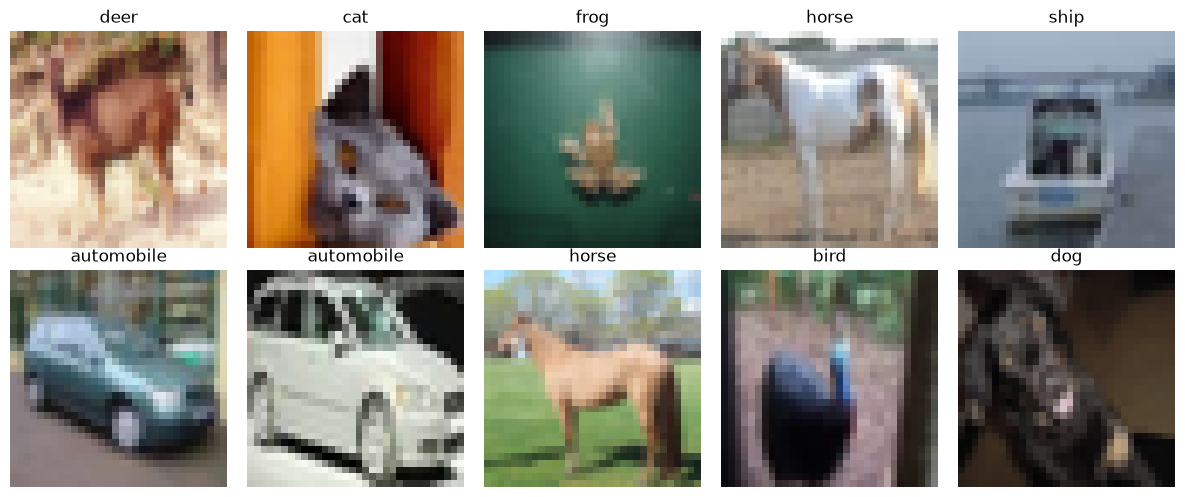

In [4]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for axis, index in zip(axes.flat, train_indices[:10]):
    axis.imshow(all_images[index])
    axis.set_title(class_names[all_labels[index]])
    axis.axis('off')
plt.tight_layout()

## 5. Kiến trúc TinyCAE

Encoder gồm một lớp Conv2D stride 2, một lớp DepthwiseConv2D stride 2 và hai lớp Conv2D 1 × 1. Đầu ra encoder có kích thước 8 × 8 × 16. Decoder sử dụng các lớp Conv2D xen kẽ hai phép upsampling nearest-neighbor để tái tạo tensor 32 × 32 × 3. Lớp cuối dùng sigmoid nhằm giới hạn đầu ra trong miền `[0,1]`. Kiến trúc ưu tiên số lượng toán tử nhỏ và khả năng tương thích TensorFlow Lite Micro.

In [5]:
tf.keras.utils.set_random_seed(SEED)

def build_models():
    encoder_input = tf.keras.Input((32, 32, 3), name='rgb_input')
    x = tf.keras.layers.Conv2D(32, 3, strides=2, padding='same', activation='relu', name='enc_conv_s2')(encoder_input)
    x = tf.keras.layers.DepthwiseConv2D(3, strides=2, padding='same', activation='relu', name='enc_depthwise_s2')(x)
    x = tf.keras.layers.Conv2D(32, 1, padding='same', activation='relu', name='enc_pointwise')(x)
    latent = tf.keras.layers.Conv2D(16, 1, padding='same', name='latent')(x)
    encoder = tf.keras.Model(encoder_input, latent, name='tinycae_encoder')

    decoder_input = tf.keras.Input((8, 8, 16), name='latent_input')
    x = tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu', name='dec_conv_64')(decoder_input)
    x = tf.keras.layers.UpSampling2D(2, interpolation='nearest', name='dec_upsample_1')(x)
    x = tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu', name='dec_conv_32')(x)
    x = tf.keras.layers.UpSampling2D(2, interpolation='nearest', name='dec_upsample_2')(x)
    x = tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu', name='dec_conv_16')(x)
    reconstruction = tf.keras.layers.Conv2D(3, 3, padding='same', activation='sigmoid', name='rgb_output')(x)
    decoder = tf.keras.Model(decoder_input, reconstruction, name='tinycae_decoder')
    autoencoder = tf.keras.Model(encoder_input, decoder(encoder(encoder_input)), name='tinycae')
    return encoder, decoder, autoencoder

encoder, decoder, autoencoder = build_models()
print('Encoder output:', encoder.output_shape, '| params:', encoder.count_params())
print('Decoder output:', decoder.output_shape, '| params:', decoder.count_params())
assert encoder.output_shape == (None, 8, 8, 16)
assert autoencoder.output_shape == (None, 32, 32, 3)
encoder.summary()

Encoder output: (None, 8, 8, 16) | params: 2800
Decoder output: (None, 32, 32, 3) | params: 32803


Model: "tinycae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_input (InputLayer)          │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv_s2 (Conv2D)            │ (None, 16, 16, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_depthwise_s2                │ (None, 8, 8, 32)       │           320 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_pointwise (Conv2D)          │ (None, 8, 8, 32)       │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Conv2D)                 │ (None, 8, 8, 16)       │           528 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,800 (10.94 KB)

 Trainable params: 2,800 (10.94 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Hàm mất mát và pipeline dữ liệu

Hàm mất mát kết hợp sai số bình phương trung bình và độ tương đồng cấu trúc:

$$L = 0{,}9 \times MSE + 0{,}1 \times (1-SSIM).$$

Ảnh `uint8` được chuẩn hóa về `[0,1]`. Pipeline `tf.data` thực hiện shuffle có seed, batching và prefetch để duy trì tính tái lập và giảm thời gian chờ dữ liệu.

In [6]:
def reconstruction_loss(y_true, y_pred):
    mse = tf.reduce_mean(tf.math.squared_difference(y_true, y_pred), axis=(1, 2, 3))
    ssim = tf.image.ssim(y_true, y_pred, max_val=1.0)
    return tf.reduce_mean(0.9 * mse + 0.1 * (1.0 - ssim))

def make_dataset(images, batch_size, training):
    ds = tf.data.Dataset.from_tensor_slices(images)
    if training:
        ds = ds.shuffle(min(len(images), 10_000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x: tf.cast(x, tf.float32) / 255.0, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x: (x, x), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

## 7. Cấu hình thí nghiệm

Hai chế độ được định nghĩa. Chế độ smoke test sử dụng 256 ảnh train, 64 ảnh validation và 1 epoch để xác minh pipeline. Chế độ chính thức sử dụng 45.000 ảnh train, 5.000 ảnh validation, batch size 128 và tối đa 100 epoch. Kết quả nghiên cứu chỉ sử dụng chế độ chính thức.

In [12]:
QUICK_RUN = False

if QUICK_RUN:
    selected_train = train_indices[:256]
    selected_validation = validation_indices[:64]
    epochs = 1
    batch_size = 64
    run_name = 'notebook_smoke'
else:
    selected_train = train_indices
    selected_validation = validation_indices
    epochs = 100
    batch_size = 128
    run_name = 'notebook_baseline'

train_images = all_images[selected_train]
validation_images = all_images[selected_validation]
train_ds = make_dataset(train_images, batch_size, training=True)
validation_ds = make_dataset(validation_images, batch_size, training=False)
print(run_name, len(train_images), len(validation_images), epochs, batch_size)

notebook_baseline 45000 5000 100 128


## 8. Quy trình huấn luyện

Mô hình được tối ưu bằng Adam với learning rate $10^{-3}$. Checkpoint được lựa chọn theo validation loss thấp nhất. Early stopping có patience 10 và khôi phục trọng số tốt nhất, qua đó hạn chế overfitting và tránh sử dụng epoch cuối một cách tùy ý.

In [13]:
run_dir = PROJECT_ROOT / 'models' / 'tinycae' / run_name
run_dir.mkdir(parents=True, exist_ok=True)

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=reconstruction_loss,
    metrics=[tf.keras.metrics.MeanSquaredError(name='mse')],
)
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(run_dir / 'best.weights.h5', monitor='val_loss', save_best_only=True, save_weights_only=True),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    tf.keras.callbacks.CSVLogger(run_dir / 'training_log.csv'),
]

started = time.perf_counter()
history = autoencoder.fit(train_ds, validation_data=validation_ds, epochs=epochs, callbacks=callbacks, verbose=2)
print(f'Thời gian: {time.perf_counter() - started:.2f} giây')

Epoch 1/100


d:\projects\iot-final\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 - 24s - 67ms/step - loss: 0.0412 - mse: 0.0122 - val_loss: 0.0264 - val_mse: 0.0066
Epoch 2/100
352/352 - 25s - 71ms/step - loss: 0.0222 - mse: 0.0049 - val_loss: 0.0199 - val_mse: 0.0040
Epoch 3/100
352/352 - 19s - 53ms/step - loss: 0.0187 - mse: 0.0038 - val_loss: 0.0174 - val_mse: 0.0033
Epoch 4/100
352/352 - 18s - 52ms/step - loss: 0.0165 - mse: 0.0033 - val_loss: 0.0155 - val_mse: 0.0029
Epoch 5/100
352/352 - 19s - 53ms/step - loss: 0.0149 - mse: 0.0029 - val_loss: 0.0143 - val_mse: 0.0027
Epoch 6/100
352/352 - 24s - 69ms/step - loss: 0.0138 - mse: 0.0026 - val_loss: 0.0134 - val_mse: 0.0025
Epoch 7/100
352/352 - 21s - 59ms/step - loss: 0.0131 - mse: 0.0025 - val_loss: 0.0134 - val_mse: 0.0028
Epoch 8/100
352/352 - 38s - 108ms/step - loss: 0.0125 - mse: 0.0024 - val_loss: 0.0123 - val_mse: 0.0022
Epoch 9/100
352/352 - 44s - 125ms/step - loss: 0.0121 - mse: 0.0023 - val_loss: 0.0118 - val_mse: 0.0021
Epoch 10/100
352/352 - 34s - 97ms/step - loss: 0.0117 - mse: 0.0022 - val_

## 9. Phân tích đường cong hội tụ

Train loss và validation loss được biểu diễn theo epoch. Khoảng cách giữa hai đường cong phản ánh mức độ khái quát hóa; validation loss là tiêu chí lựa chọn checkpoint chính thức.

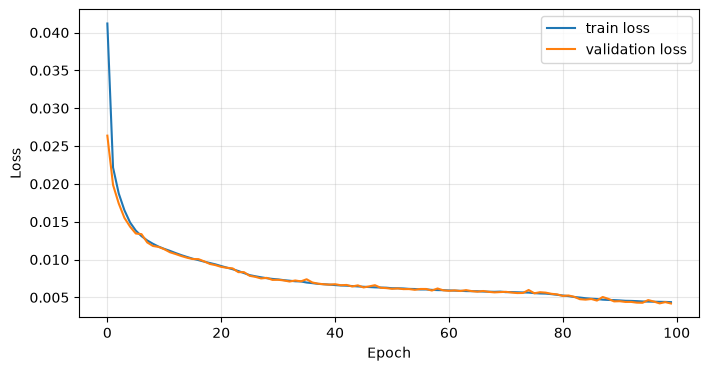

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 10. Đánh giá chất lượng tái tạo

Mô hình được đánh giá bằng PSNR và SSIM trung bình trên validation. Các cặp ảnh gốc–tái tạo được trình bày để bổ sung đánh giá định lượng bằng kiểm tra trực quan về màu sắc, cấu trúc và chi tiết.

PSNR trung bình: 31.6340 dB
SSIM trung bình: 0.965298


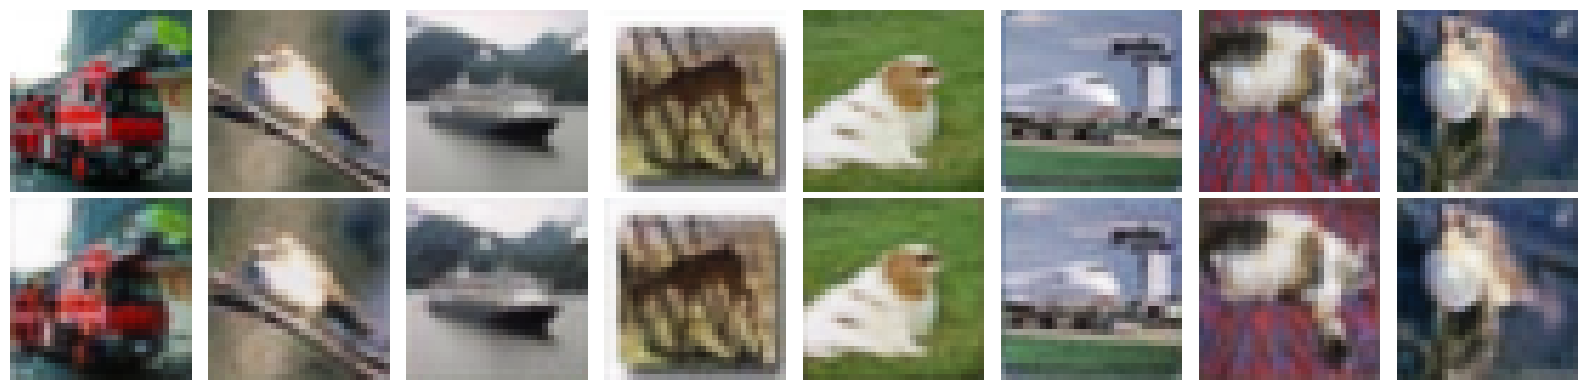

In [16]:
references = validation_images.astype(np.float32) / 255.0
predictions = autoencoder.predict(references, batch_size=batch_size, verbose=0)
psnr = tf.image.psnr(references, predictions, max_val=1.0).numpy()
ssim = tf.image.ssim(references, predictions, max_val=1.0).numpy()
print(f'PSNR trung bình: {psnr.mean():.4f} dB')
print(f'SSIM trung bình: {ssim.mean():.6f}')

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(references[i])
    axes[0, i].axis('off')
    axes[1, i].imshow(np.clip(predictions[i], 0, 1))
    axes[1, i].axis('off')
axes[0, 0].set_ylabel('Gốc')
axes[1, 0].set_ylabel('Tái tạo')
plt.tight_layout()

## 11. Lưu trữ hiện vật thí nghiệm

Encoder, decoder và autoencoder được lưu riêng ở định dạng Keras. Tệp metrics ghi cấu hình tập dữ liệu, PSNR, SSIM và kích thước latent. Các hiện vật này là đầu vào của thí nghiệm lượng tử hóa INT8.

In [17]:
FP32_DIR = PROJECT_ROOT / 'models' / 'tinycae' / 'baseline'
encoder.save(run_dir / 'encoder.keras')
decoder.save(run_dir / 'decoder.keras')
autoencoder.save(run_dir / 'autoencoder.keras')
metrics = {
    'run_name': run_name,
    'quick_run': QUICK_RUN,
    'train_images': len(train_images),
    'validation_images': len(validation_images),
    'psnr_db': float(psnr.mean()),
    'ssim': float(ssim.mean()),
    'latent_shape': [8, 8, 16],
}
(run_dir / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print(json.dumps(metrics, indent=2))
print('Đã lưu tại:', run_dir)

{
  "run_name": "notebook_baseline",
  "quick_run": false,
  "train_images": 45000,
  "validation_images": 5000,
  "psnr_db": 31.633981704711914,
  "ssim": 0.9652977585792542,
  "latent_shape": [
    8,
    8,
    16
  ]
}
Đã lưu tại: d:\projects\iot-final\models\tinycae\notebook_baseline
